# 04 · Method B: Time-Series Statistics + Machine Learning

Method A encodes investor intuition as fixed rules. Method B asks the same question
("is this a durable trend or noise?") with **no hand-chosen signals**. It uses only the
statistical behaviour of the time series, plus a model that **learns** what persistence
looks like from hundreds of past examples.

| Part | Technique | Output |
|---|---|---|
| **B1** | STL decomposition, ADF unit-root test, PELT structural breaks, Theil–Sen slope on SF monthly search interest | statistical persistence score |
| **B2** | Persistence classifier trained on YC tag histories, 2008–2022 (model chosen by time-series CV from logistic or gradient boosting): *"will founders still be building this theme 3 years from now?"* | P(persist) |
| **B3** | Granger causality + lead–lag cross-correlation, SF → SEA | does SF predict SEA, and with how much lag? |

**Score B = mean(B1, B2).** B3 is kept separate because it measures *transfer*, not trend
validity. Notebook 06 uses it for timing.

**Why B2 matters:** only 19 events are labelled, which is far too few to train a model honestly.
The YC tag history provides **thousands** of "theme was rising in year *t*: did it last?"
examples, labelled automatically by what happened later. That is enough data for real ML,
with a proper time-based train/test split.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
import ruptures as rpt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

sys.path.insert(0, str(Path.cwd().parent))
from radar.config import PROC, FIG, SECTORS, LABELLED, END_YEAR
warnings.filterwarnings("ignore")

monthly = pd.read_parquet(PROC / "panel_monthly.parquet")
yearly = pd.read_parquet(PROC / "panel_yearly.parquet")
sectors = pd.read_parquet(PROC / "sectors.parquet")
M = {k: g.set_index("date")["value"].sort_index() for k, g in monthly.groupby(["sector", "signal"])}
Y = {k: g.set_index("year")["value"].sort_index() for k, g in yearly.groupby(["sector", "signal"])}
EMPTY = pd.Series(dtype=float)
EMPTY_M = pd.Series(dtype=float, index=pd.DatetimeIndex([]))

def m_upto(s, sig, t):
    x = M.get((s, sig), EMPTY_M)
    return x[x.index <= pd.Timestamp(f"{t}-12-31")]

## B1 · Statistical persistence tests on SF monthly search interest
For each sector and year *t*, using the last 72 months up to *t*:
* **Trend strength** (Hyndman's F_T from STL): how much of the variance is smooth trend
  rather than noise. 0 = all noise, 1 = all trend.
* **ADF p-value:** a low p-value means the series is mean-reverting, so shocks die out
  (hype). A high p-value means shocks persist (a trend). Mapped to `min(p/0.5, 1)`.
* **Regime hold (PELT breaks):** the series is split into regimes. Compare the
  mean of the current regime with the best regime so far. Collapsing after a peak gives a low value.
* **Slope:** Theil–Sen slope of the log series over the last 36 months, squashed to 0–1.

In [2]:
def b1_features(s, t):
    m = m_upto(s, "gt_sf", t)
    if not (m > 0).any(): return {}
    m = m[m.index >= m[m > 0].index.min()].tail(72)
    if len(m) < 36: return {}
    x = np.log(m + 0.05 * m.max())                                 # scale-free log
    f = {}
    try:
        r = STL(x.values, period=12, robust=True).fit()
        f["trend_strength"] = max(0.0, 1 - np.var(r.resid) / np.var(r.trend + r.resid))
    except Exception:
        f["trend_strength"] = np.nan
    try:
        f["adf_p"] = adfuller(x.values, regression="c", autolag="AIC")[1]
    except Exception:
        f["adf_p"] = np.nan
    try:
        algo = rpt.Pelt(model="l2", min_size=6, jump=1).fit(x.values.reshape(-1, 1))
        bkps = algo.predict(pen=3 * np.log(len(x)) * max(np.var(np.diff(x.values)), 1e-6))
    except Exception:
        bkps = [len(x)]                                            # no detectable break
    segs = np.split(x.values, bkps[:-1])
    lvl = np.exp(np.array([sg.mean() for sg in segs]))
    f["regime_hold"] = float(lvl[-1] / lvl.max())
    f["n_breaks"] = len(bkps) - 1
    last = x.tail(36)
    f["slope36"] = stats.theilslopes(last.values, np.arange(len(last)))[0] * 12   # log-units / year
    return f

def b1_score(f):
    if not f: return np.nan
    parts = [f.get("trend_strength"), min(f.get("adf_p", np.nan) / 0.5, 1.0),
             f.get("regime_hold"), 1 / (1 + np.exp(-3 * f.get("slope36", np.nan)))]
    parts = [p for p in parts if p is not None and not np.isnan(p)]
    return float(np.mean(parts)) if len(parts) >= 3 else np.nan

b1_rows = []
for s in SECTORS:
    for t in range(2009, END_YEAR + 1):
        f = b1_features(s, t)
        b1_rows.append(dict(sector=s, year=t, **f, score_B1=b1_score(f)))
B1 = pd.DataFrame(b1_rows)
B1.groupby(B1.sector.map(sectors.label))[["trend_strength", "adf_p", "regime_hold", "slope36", "score_B1"]].mean().round(2)

,trend_strength,adf_p,regime_hold,slope36,score_B1
sector,,,,,
ambiguous,0.63,0.41,0.59,-0.07,0.56
boom,0.69,0.47,0.93,0.14,0.71
candidate,0.65,0.36,0.74,-0.01,0.60
noise,0.55,0.38,0.79,0.07,0.60


## B2 · ML persistence classifier trained on YC tag histories
**Training set:** every (YC tag, year *t*) with any activity in the previous 5 years.
**Label:** `persist = 1` if its share at *t*+2..*t*+3 is still ≥ 80% of its share at *t*−1..*t*.
This is "did founders keep building it, or was it a one-batch fad?"

**Features:** all relative and dynamic (growth over several horizons, acceleration,
volatility, drawdown, age, run length). Absolute share is excluded because sector regexes
and single YC tags differ in scale.

**Validation:** strictly by time, in two stages.
1. **Model selection:** rolling-origin cross-validation *inside the training era*. Train on
   years ≤ k−3 and predict year k, for k = 2012…2016. The model with the best CV AUC wins.
2. **Held-out test:** 2017–2022, looked at once and reported whatever the result.

The candidates range from one feature (founder momentum) to a gradient-boosted model on all 9
features. If the simple model wins, we use the simple model.

In [3]:
tag_share = pd.read_parquet(PROC / "yc_tag_share.parquet")
tag_share.columns = tag_share.columns.astype(int)
EPS = 2e-3

def dyn_features(x, t):
    """x: yearly share series (index=year). Features at year t using data <= t."""
    x = x[x.index <= t]
    if len(x) < 5 or x.loc[t - 4:t].sum() == 0: return None
    v = lambda a, b: x.loc[a:b].mean()
    g1 = np.log((x.get(t, 0) + EPS) / (x.get(t - 1, 0) + EPS))
    g1p = np.log((x.get(t - 1, 0) + EPS) / (x.get(t - 2, 0) + EPS))
    g2 = np.log((v(t - 1, t) + EPS) / (v(t - 3, t - 2) + EPS))
    g4 = np.log((v(t - 1, t) + EPS) / (v(t - 5, t - 4) + EPS)) if t - 5 >= x.index.min() else g2
    yoy = np.diff(np.log(x.loc[t - 5:t].values + EPS))
    nz = x[x > 0]
    up = 0
    for d in yoy[::-1]:
        if d > 0: up += 1
        else: break
    return dict(g1=g1, g2=g2, g4=g4, accel=g1 - g1p, vol=np.std(yoy),
                drawdown=v(t - 1, t) / max(x.rolling(2).mean().max(), 1e-12),
                age=t - nz.index.min() if len(nz) else 0, run_up=up)

FEATS = ["g1", "g2", "g4", "accel", "vol", "drawdown", "age", "run_up"]
rows = []
for tag, x in tag_share.iterrows():
    for t in range(2008, END_YEAR + 1):
        f = dyn_features(x, t)
        if f is None: continue
        lab = np.nan
        if t + 3 <= 2025:
            lab = int(x.loc[t + 2:t + 3].mean() >= 0.8 * x.loc[t - 1:t].mean())
        rows.append(dict(tag=tag, year=t, **f, persist=lab))
D = pd.DataFrame(rows)
Dl = D.dropna(subset=["persist"])
print(f"labelled examples: {len(Dl)} tag-years from {Dl.tag.nunique()} YC tags  (base rate persist = {Dl.persist.mean():.2f})")

CANDS = {
    "momentum only (logit on g1)": (["g1"], lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    "logistic, all features":      (FEATS, lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=1000))),
    "gradient boosting, all":      (FEATS, lambda: HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=150,
                                                                             l2_regularization=1.0, min_samples_leaf=30, random_state=0)),
}

def rolling_cv(feats, make, years=range(2012, 2017)):
    ps, ys = [], []
    for k in years:
        tr, te = Dl[Dl.year <= k - 3], Dl[Dl.year == k]
        if len(te) < 5 or tr.persist.nunique() < 2: continue
        ps += list(make().fit(tr[feats], tr.persist).predict_proba(te[feats])[:, 1]); ys += list(te.persist)
    return roc_auc_score(ys, ps)

train, test = Dl[Dl.year <= 2016], Dl[Dl.year >= 2017]
res = {}
for name, (feats, make) in CANDS.items():
    p = make().fit(train[feats], train.persist).predict_proba(test[feats])[:, 1]
    res[name] = dict(CV_AUC_2012_16=rolling_cv(feats, make), TEST_AUC_2017_22=roc_auc_score(test.persist, p),
                     TEST_Brier=brier_score_loss(test.persist, p), p=p)
cmp = pd.DataFrame(res).T.drop(columns="p").astype(float).round(3)
BEST = cmp.CV_AUC_2012_16.idxmax()
print("selected by CV:", BEST)
cmp

labelled examples: 1865 tag-years from 167 YC tags  (base rate persist = 0.64)


selected by CV: logistic, all features


,CV_AUC_2012_16,TEST_AUC_2017_22,TEST_Brier
momentum only (logit on g1),0.514,0.571,0.226
"logistic, all features",0.590,0.611,0.235
"gradient boosting, all",0.588,0.577,0.229


**How to read this:** an AUC of 0.5 is a coin flip. Predicting whether founders keep building a theme is
**hard**. The best model, a logistic regression on all 9 shape features chosen by CV, reaches
**AUC ≈ 0.61** on held-out 2017–22, against 0.57 for founder momentum alone. Gradient boosting
overfits and does no better. That's a modest but real signal *about founder behaviour*.
Notebook 05 tests whether it also predicts **SEA booms**. Spoiler: it does, but **inverted**. Founders
pile into hype.

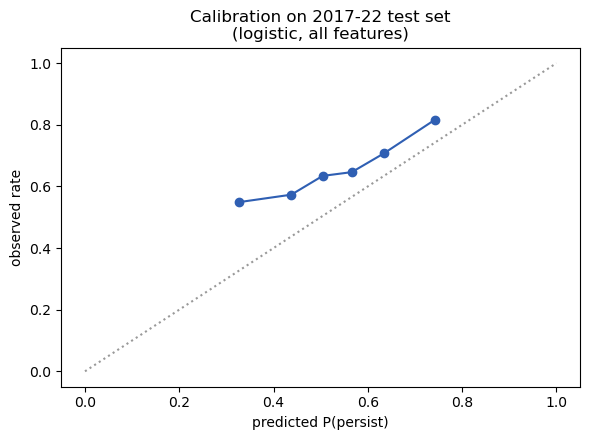

In [4]:
feats_best, make_best = CANDS[BEST]
fig, ax = plt.subplots(figsize=(6, 4.5))
pt, pp = calibration_curve(test.persist, res[BEST]["p"], n_bins=6, strategy="quantile")
ax.plot(pp, pt, "o-", color="#2f5fb3"); ax.plot([0, 1], [0, 1], ":", color="#999")
ax.set_xlabel("predicted P(persist)"); ax.set_ylabel("observed rate")
ax.set_title(f"Calibration on 2017-22 test set\n({BEST})")
plt.tight_layout(); plt.savefig(FIG / "04_b2_calibration.png", dpi=150); plt.show()

### Applying B2 to our sectors, point-in-time
For each year *t* the model is **retrained from scratch using only examples whose outcome
was already known by *t*** (that is, *t'* + 3 ≤ *t*). It then scores the sector's own YC
founder-share history at *t*. This is what you could actually have run in that year.

In [5]:
def sector_yc(s):
    return Y.get((s, "yc_share"), EMPTY)

b2_rows = []
for t in range(2009, END_YEAR + 1):
    tr = Dl[Dl.year + 3 <= t]
    ok = len(tr) >= 150 and tr.persist.nunique() == 2
    if ok:
        mdl = make_best().fit(tr[feats_best], tr.persist)
    for s in SECTORS:
        x = sector_yc(s)
        f = dyn_features(x, t) if len(x) else None
        p = np.nan
        if ok and f is not None:
            p = mdl.predict_proba(pd.DataFrame([f])[feats_best])[0, 1]
        b2_rows.append(dict(sector=s, year=t, score_B2=p, n_train=len(tr)))
B2 = pd.DataFrame(b2_rows)
print("first year B2 is available:", B2.dropna(subset=["score_B2"]).year.min())

first year B2 is available: 2014


## B3 · Does SF lead SEA? (Granger causality + lag)
Tested on monthly 12-month log-changes over the full history (descriptive, used for
timing). **Granger p < 0.05** means past SF interest helps forecast SEA interest beyond
SEA's own past. **Lag** = the month offset that maximises the SF→SEA cross-correlation.

In [6]:
def granger_lag(s, t=END_YEAR, maxlag=24):
    sf, sea = m_upto(s, "gt_sf", t), m_upto(s, "gt_sea", t)
    j = pd.concat([sf, sea], axis=1, keys=["sf", "sea"]).dropna()
    j = j[(j > 0).all(axis=1).cummax()]
    if len(j) < 60: return dict(granger_p=np.nan, lag_months=np.nan, xcorr=np.nan)
    d = np.log(j + 0.05 * j.max()).diff(12).dropna()
    try:
        g = grangercausalitytests(d[["sea", "sf"]], maxlag=12, verbose=False)
        gp = min(v[0]["ssr_ftest"][1] for v in g.values())
    except Exception:
        gp = np.nan
    cc = {L: d["sea"].corr(d["sf"].shift(L)) for L in range(0, maxlag + 1)}
    L = max(cc, key=lambda k: cc[k] if not np.isnan(cc[k]) else -9)
    return dict(granger_p=gp, lag_months=L, xcorr=cc[L])

B3 = pd.DataFrame({s: granger_lag(s) for s in SECTORS}).T.astype(float)
B3["label"] = sectors.label
B3.to_parquet(PROC / "method_B3_transfer.parquet")
print(B3.groupby("label")[["granger_p", "lag_months", "xcorr"]].median().round(2))
B3.sort_values("label").round(3)

           granger_p  lag_months  xcorr
label                                  
ambiguous       0.05         3.0   0.40
boom            0.01        10.0   0.28
candidate       0.07         6.0   0.30
noise           0.01         0.0   0.73


,granger_p,lag_months,xcorr,label
edtech,0.796,16.0,0.153,ambiguous
b2b_saas,0.020,3.0,0.338,ambiguous
p2p_lending,0.005,0.0,0.493,ambiguous
insurtech,NaN,NaN,NaN,ambiguous
telemedicine,0.090,3.0,0.465,ambiguous
crypto_exchanges,NaN,NaN,NaN,ambiguous
ride_hailing,0.000,5.0,0.542,boom
food_delivery,0.009,14.0,0.343,boom
video_streaming,0.002,0.0,0.174,boom
digital_payments,0.167,24.0,0.099,boom


## B4 · Is the SF → SEA link real, or does everything just move together?
A significant Granger test alone proves little. SF and SEA search interest could both be riding the same
background forces: internet and smartphone adoption, COVID, and general shifts in search behaviour. So we run a
**placebo test**:

* **Matched pairs:** SF interest in sector X → SEA interest in the *same* sector X
* **Placebo pairs:** SF interest in sector X → SEA interest in a *different* sector Y (e.g. SF ride-hailing → SEA NFTs)

If SF→SEA transmission is sector-specific, matched pairs should be significant **more often** than placebo
pairs. The placebo rate is the background level of spurious "prediction".

**Scope:** labelled sectors whose attention series come from Google Trends (not the Wikipedia fallback), over their
full history. Matched-pair p-values are also corrected for testing many sectors at once (Benjamini–Hochberg FDR).

**Caveats:** Granger causality means "helps forecast", not "causes". The tests use overlapping 12-month changes,
which overstates significance. That is one reason the placebo baseline is high, and why comparing matched
against placebo is more trustworthy than any single p-value.

In [7]:
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact

gt_meta = pd.read_parquet(PROC / "gt_meta.parquet")
pool = [s for s in LABELLED
        if gt_meta.loc[s].get("gt_sf_source") == "google trends"
        and len(m_upto(s, "gt_sf", END_YEAR)) and len(m_upto(s, "gt_sea", END_YEAR))]

def granger_p(sf, sea, maxlag=12):
    """min p-value over lags 1..12 for 'past SF changes help forecast SEA changes'."""
    j = pd.concat([sf, sea], axis=1, keys=["sf", "sea"]).dropna()
    j = j[(j > 0).all(axis=1).cummax()]
    if len(j) < 60: return np.nan
    d = np.log(j + 0.05 * j.max()).diff(12).dropna()
    try:
        g = grangercausalitytests(d[["sea", "sf"]], maxlag=maxlag, verbose=False)
        return min(v[0]["ssr_ftest"][1] for v in g.values())
    except Exception:
        return np.nan

SF_ = {s: m_upto(s, "gt_sf", END_YEAR) for s in pool}
SEA_ = {s: m_upto(s, "gt_sea", END_YEAR) for s in pool}
matched = pd.Series({s: granger_p(SF_[s], SEA_[s]) for s in pool}).dropna()
placebo = np.array([granger_p(SF_[a], SEA_[b]) for a in pool for b in pool if a != b])
placebo = placebo[~np.isnan(placebo)]

rej, p_fdr, _, _ = multipletests(matched.values, method="fdr_bh")
B4 = pd.DataFrame({"label": sectors.label.reindex(matched.index), "granger_p": matched,
                   "p_fdr": p_fdr, "significant_after_fdr": rej}).sort_values(["label", "granger_p"])
B4.to_parquet(PROC / "method_B4_placebo.parquet")
B4.round(4)

,label,granger_p,p_fdr,significant_after_fdr
ride_hailing,boom,0.0005,0.0016,True
video_streaming,boom,0.0024,0.0063,True
retail_investing,boom,0.0066,0.0147,True
food_delivery,boom,0.0093,0.0167,True
digital_banks,boom,0.0580,0.0653,False
digital_payments,boom,0.1675,0.1773,False
bnpl,boom,0.2113,0.2113,False
play_to_earn,noise,0.0000,0.0000,True
consumer_3d_printing,noise,0.0000,0.0000,True
social_audio,noise,0.0000,0.0001,True


In [8]:
a, b = int((matched < 0.05).sum()), int((matched >= 0.05).sum())
c, d = int((placebo < 0.05).sum()), int((placebo >= 0.05).sum())
odds, p_fisher = fisher_exact([[a, b], [c, d]], alternative="greater")
summary_b4 = pd.DataFrame({
    "pairs": [len(matched), len(placebo)],
    "share significant (p<0.05)": [a / len(matched), c / len(placebo)],
    "median p": [np.median(matched), np.median(placebo)],
}, index=["matched (same sector)", "placebo (different sectors)"]).round(3)
print(f"Matched vs placebo, Fisher exact (one-sided): odds ratio = {odds:.1f}, p = {p_fisher:.3f}")
print(f"After FDR correction, {rej.mean():.0%} of matched sectors remain significant")
for l in ["boom", "noise"]:
    sub = B4[B4.label == l]
    print(f"  {l:5s}: {(sub.granger_p < 0.05).sum()} of {len(sub)} significant (raw), "
          f"{sub.significant_after_fdr.sum()} after FDR")
summary_b4

Matched vs placebo, Fisher exact (one-sided): odds ratio = 4.2, p = 0.012
After FDR correction, 67% of matched sectors remain significant
  boom : 4 of 7 significant (raw), 4 after FDR
  noise: 11 of 11 significant (raw), 8 after FDR


,pairs,share significant (p<0.05),median p
matched (same sector),18,0.833,0.008
placebo (different sectors),306,0.542,0.041


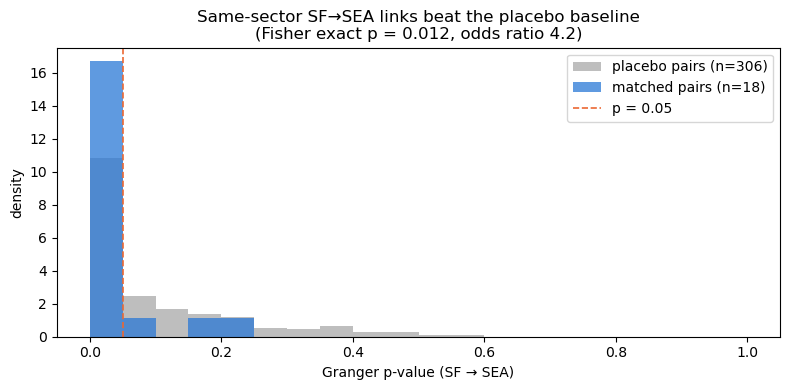

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 21)
ax.hist(placebo, bins=bins, density=True, alpha=0.55, color="#8a8a8a", label=f"placebo pairs (n={len(placebo)})")
ax.hist(matched, bins=bins, density=True, alpha=0.75, color="#2a78d6", label=f"matched pairs (n={len(matched)})")
ax.axvline(0.05, color="#eb6834", ls="--", lw=1.2, label="p = 0.05")
ax.set_xlabel("Granger p-value (SF → SEA)"); ax.set_ylabel("density")
ax.set_title(f"Same-sector SF→SEA links beat the placebo baseline\n(Fisher exact p = {p_fisher:.3f}, odds ratio {odds:.1f})")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "04_b4_placebo.png", dpi=150); plt.show()

### What B4 shows
* **There is a sector-specific SF → SEA link.** Same-sector pairs are significant more often than placebo pairs,
  so SF interest in a sector carries information about later SEA interest in *that* sector, beyond the
  background co-movement between the two markets.
* **Much of the raw correlation is background.** A large share of placebo pairs also come out "significant".
  A single sector's Granger result on its own is weak evidence.
* **The link is tighter for hype than for booms.** Hype transmits through the global news cycle almost
  instantly. Real booms pass through local operators, regulation and payment rails, so they arrive later and less
  tightly. That matches the synchronisation finding in notebook 05.
* **What this does *not* show:** that SF booms *cause* SEA booms, or that SEA *markets* (revenue, funding)
  follow SF. Both series here measure search attention, and the boom/hype labels are judgement calls.

## Combine: Score B = mean(B1, B2)

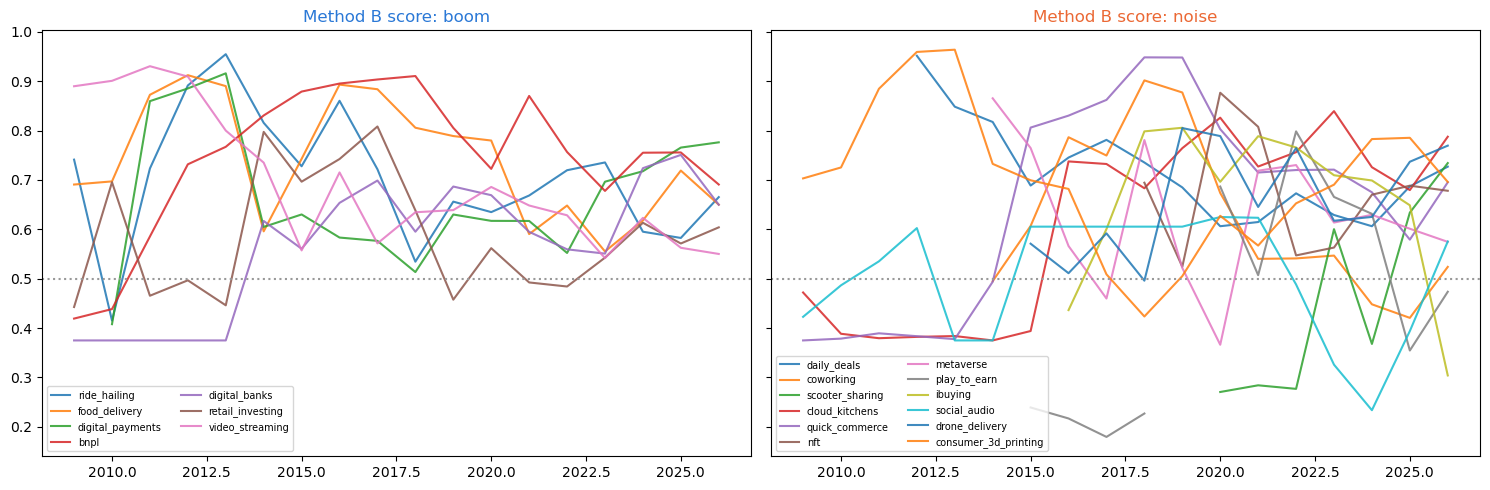

,score_B1,score_B2,score_B
label,,,
ambiguous,0.562,0.469,0.494
boom,0.708,0.605,0.672
candidate,0.595,0.595,0.574
noise,0.601,0.694,0.619


In [10]:
B = B1.merge(B2, on=["sector", "year"], how="outer")
B["score_B"] = B[["score_B1", "score_B2"]].mean(axis=1, skipna=True)
B.loc[B[["score_B1", "score_B2"]].isna().all(axis=1), "score_B"] = np.nan
B["label"] = B.sector.map(sectors.label)
B.to_parquet(PROC / "method_B_scores.parquet")

COL = {"boom": "#2a78d6", "noise": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, lbl in zip(axes, ["boom", "noise"]):
    for s in [x for x in LABELLED if sectors.label[x] == lbl]:
        d = B[B.sector == s].set_index("year")["score_B"]
        ax.plot(d.index, d.values, lw=1.5, alpha=.85, label=s)
    ax.axhline(0.5, color="#999", ls=":"); ax.set_title(f"Method B score: {lbl}", color=COL[lbl]); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "04_scoreB_trajectories.png", dpi=150); plt.show()
B.groupby("label")[["score_B1", "score_B2", "score_B"]].mean().round(3)